In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt
import scienceplots 
import numpy as np
plt.style.use(['science'])

## Fyzikální reziduum a automatická diferenciace

*Navazuje na slidy 3–5: Co NN dělá?, Loss function a Derivace.*

PINN představuje hledané řešení parametrickou funkcí a její parametry upravuje tak, aby splňovala fyzikální rovnici. Pro jednoduchost zde síť nahrazuje jediná funkce $\phi_w(x)=\tanh(wx)$ s jednou učenou vahou $w$. V pěti vnitřních (kolokačních) bodech kontrolujeme jednorozměrnou Poissonovu rovnici:

$$
\phi''(x)=-\frac{\rho}{\varepsilon},\qquad
r_w(x)=\phi_w''(x)+\frac{\rho}{\varepsilon},\qquad
\mathcal L_{\mathrm{fyz}}=\sum_i r_w(x_i)^2.
$$

V kódu volíme $\rho/\varepsilon=1$. Reziduum říká, o kolik aktuální funkce v daném bodě porušuje rovnici; jeho čtverce tvoří společnou ztrátu.

`requires_grad=True` zapíná sledování závislostí. Dvě volání `torch.autograd.grad` počítají nejprve $\phi'$ a poté $\phi''$ podle polohy. `create_graph=True` zachová závislost derivací na váze, aby šlo následně derivovat i ztrátu. Trik se součtem funguje, protože každý výstup $\phi(x_i)$ závisí pouze na odpovídajícím vstupu $x_i$.

`loss.backward()` pak vypočítá $\mathrm d\mathcal L/\mathrm dw$: jak váha ovlivňuje chybu ve všech bodech dohromady. Buňka vypíše derivace, rezidua, ztrátu a její gradient; váhu zatím neaktualizuje a neřeší okrajové podmínky.


In [3]:
# Pět bodů, ve kterých kontrolujeme Poissonovu rovnici
x = torch.linspace(0.1, 0.9, steps=5, requires_grad=True)
w = torch.tensor(2.0, requires_grad=True)
rho_over_eps = 1.0

# Jeden odhad potenciálu pro každý bod
phi = torch.tanh(w * x)

# První a druhá derivace potenciálu v každém bodě
(dphi_dx,) = torch.autograd.grad(phi.sum(), x, create_graph=True)
(d2phi_dx2,) = torch.autograd.grad(dphi_dx.sum(), x, create_graph=True)

# Jedno reziduum na bod, jedna společná ztráta
residual = d2phi_dx2 + rho_over_eps
loss = residual.square().sum()

# Jak změna společné váhy ovlivní ztrátu ze všech bodů?
loss.backward()

print("  x     φ''(x)    reziduum")
for xi, curvature, ri in zip(x, d2phi_dx2, residual):
    print(f"{xi.item():.2f}   {curvature.item():+7.3f}   {ri.item():+7.3f}")

print(f"\nZtráta: {loss.item():.3f}")
print(f"d(loss)/dw: {w.grad.item():+.3f}")

  x     φ''(x)    reziduum
0.10    -1.517    -0.517
0.30    -3.057    -2.057
0.50    -2.559    -1.559
0.70    -1.531    -0.531
0.90    -0.784    +0.216

Ztráta: 7.258
d(loss)/dw: +19.994


## Okrajové podmínky přes ztrátovou funkci

*Navazuje na slide 6: Okrajové podmínky — přes ztrátu.*

Samotná rovnice $\phi''=-1$ neurčuje řešení jednoznačně. Na intervalu $[0,1]$ proto přidáme Dirichletovy podmínky $\phi(0)=1$ a $\phi(1)=2$. První možností je penalizovat jejich nesplnění:

$$
\mathcal L=\underbrace{\sum_i\bigl(\phi_w''(x_i)+1\bigr)^2}_{\mathcal L_{\mathrm{fyz}}}
+\underbrace{\bigl(\phi_w(0)-1\bigr)^2+\bigl(\phi_w(1)-2\bigr)^2}_{\mathcal L_{\mathrm{okr}}}.
$$

`okraje` obsahuje polohy konců a `cil` požadované hodnoty potenciálu. Oba členy mají v této ukázce jednotkovou váhu. Při trénování by optimalizátor hledal kompromis mezi splněním rovnice a okrajů; podmínky jsou tímto způsobem vynucovány pouze přibližně.

**Omezení ukázky:** zvolená funkce $\tanh(wx)$ má vždy $\phi(0)=0$ a její hodnoty leží mezi $-1$ a $1$. Předepsané okraje tedy nedokáže splnit pro žádné $w$. Buňka ilustruje sestavení ztráty, nikoli úspěšné vyřešení úlohy, a sama neprovádí optimalizaci. Následující buňka ukazuje vhodnější tvar funkce pro přesné splnění okrajů.


In [4]:
x = torch.linspace(0.1, 0.9, 5, requires_grad=True)
w = torch.tensor(2.0, requires_grad=True)

phi = torch.tanh(w * x)
(dphi,) = torch.autograd.grad(phi.sum(), x, create_graph=True)
(ddphi,) = torch.autograd.grad(dphi.sum(), x, create_graph=True)

okraje = torch.tensor([0., 1.])
cil = torch.tensor([1., 2.])
loss_okraj = (torch.tanh(w * okraje) - cil).square().sum()
loss = (ddphi + 1).square().sum() + loss_okraj

## Okrajové podmínky zabudované do řešení

*Navazuje na slide 6: Okrajové podmínky — přímo přes pomocné funkce.*

Druhou možností je sestavit aproximaci tak, aby okrajové podmínky splňovala pro libovolné hodnoty parametrů:

$$
\phi_w(x)=\underbrace{1+x}_{\text{předepsané hodnoty na okrajích}}
+\underbrace{x(1-x)}_{\text{nula na obou koncích}}\,\tanh(wx).
$$

Lineární člen propojuje hodnoty $\phi(0)=1$ a $\phi(1)=2$. Učená korekce může měnit průběh uvnitř intervalu, ale na obou koncích vymizí. Okrajová ztráta proto odpadá a zbývá pouze $\mathcal L_{\mathrm{fyz}}=\sum_i(\phi_w''(x_i)+1)^2$.

Automatická diferenciace zde derivuje celý výraz včetně pomocných členů. Graf ukazuje aktuální odhad v pěti vnitřních bodech a červeně přesně splněné okrajové hodnoty. Parametr $w=2$ je stále pevně zvolený; graf tedy neukazuje natrénované řešení Poissonovy rovnice. Přesné splnění okrajů samo o sobě nezaručuje splnění rovnice uvnitř oblasti.


Text(0, 0.5, '$\\phi(x)$')

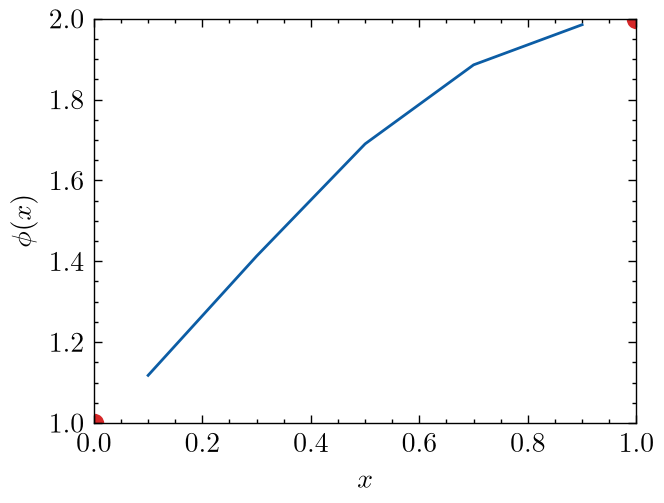

In [5]:
x = torch.linspace(0.1, 0.9, 5, requires_grad=True)
w = torch.tensor(2.0, requires_grad=True)

phi = 1 + x + x * (1 - x) * torch.tanh(w * x)
(dphi,) = torch.autograd.grad(phi.sum(), x, create_graph=True)
(ddphi,) = torch.autograd.grad(dphi.sum(), x, create_graph=True)

loss = (ddphi + 1).square().sum()

fig, ax = plt.subplots(dpi=200)
ax.plot(x.detach().numpy(), phi.detach().numpy())
x = torch.tensor([0.0, 1.0], requires_grad=True)
phi = 1 + x + x * (1 - x) * torch.tanh(w * x)
[ax.scatter(x.detach().numpy()[i], phi.detach().numpy()[i], color='tab:red') for i in [0,1]]
ax.set_xlim([0, 1])
ax.set_ylim([1, 2])
ax.set_xlabel('$x$')
ax.set_ylabel('$\\phi(x)$')

## Přímá úloha: chladnutí homogenní tyče

*Navazuje na slide 7: Příklad 1 — Difúze tepla na tyči.*

Tyč délky $L=2\,\mathrm m$ má oba konce udržované na $20\,{}^\circ\mathrm C$. Před vypnutím ohřevu dosahuje uprostřed $450\,{}^\circ\mathrm C$ a její profil je trojúhelníkový. Od času $t=0$ sledujeme dvě hodiny chladnutí bez úniku tepla pláštěm. Známá tepelná difuzivita je $\alpha=9\times10^{-5}\,\mathrm{m^2/s}$:

$$
\frac{\partial T}{\partial t}=\alpha\frac{\partial^2T}{\partial x^2},\qquad
T(x,0)=20+430\left(1-\left|\frac{2x}{L}-1\right|\right),\qquad
T(0,t)=T(L,t)=20.
$$

Síť se dvěma vstupy (poloha a čas), dvěma skrytými vrstvami po 32 neuronech a jedním výstupem aproximuje $T(x,t)$. Funkce `teplota` škáluje vstupy pomocí $L$ a `t_max` a výstup převádí na teplotu.

V každém z 3000 kroků se znovu vylosuje 256 bodů uvnitř časoprostorové oblasti. Automatické derivace v nich dávají reziduum $T_t-\alpha T_{xx}$. Celková ztráta sčítá fyzikální člen, chybu počátečního profilu ve 101 bodech a chybu obou okrajů v 51 časech. Reziduum se násobí $t_{\max}/430$ a teplotní chyby se dělí 430, aby členy měly bezrozměrné a lépe srovnatelné velikosti. Adam pak aktualizuje parametry sítě.

Plné čáry v grafu představují PINN, čárkované referenční řešení Fourierovou řadou s lichými módy; v čase nula se použije přímo zadaný profil. Sledujte shodu křivek i postupný pokles teploty. Referenční řešení slouží k ověření, do trénování nevstupuje.


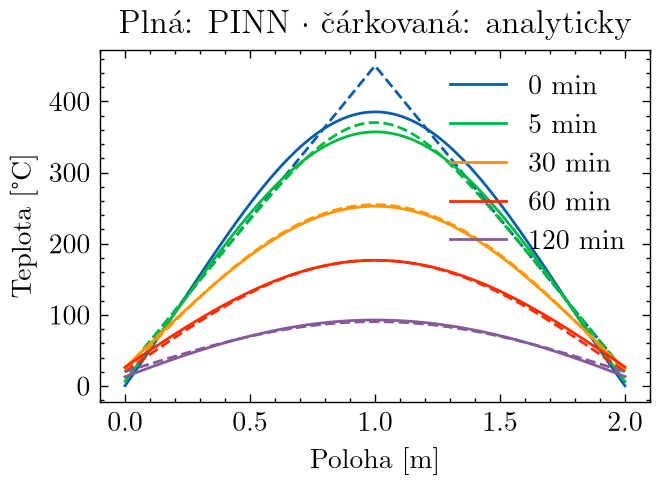

In [6]:
torch.manual_seed(7)
torch.set_num_threads(1)

L = 2.0           # délka tyče [m]
t_max = 7200.0    # dvě hodiny [s]
alpha = 9e-5      # tepelná difuzivita [m²/s]

model = nn.Sequential(
    nn.Linear(2, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 1),
)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


def teplota(x, t):
    vstup = torch.cat((x / L, t / t_max), dim=1)
    return 20 + 430 * model(vstup)


# Počáteční profil: 20 °C na koncích, 450 °C uprostřed
x0 = torch.linspace(0, L, 101).reshape(-1, 1)
T0 = 20 + 430 * (1 - (2 * x0 / L - 1).abs())

# Časy, ve kterých kontrolujeme teplotu na obou koncích
t_okr = torch.linspace(0, t_max, 51).reshape(-1, 1)

for krok in range(3000):
    optimizer.zero_grad()

    # Rovnice tepla uvnitř tyče
    x = (L * torch.rand(256, 1)).requires_grad_()
    t = (t_max * torch.rand(256, 1)).requires_grad_()
    T = teplota(x, t)
    T_x, T_t = torch.autograd.grad(T.sum(), (x, t), create_graph=True)
    (T_xx,) = torch.autograd.grad(T_x.sum(), x, create_graph=True)
    loss_fyz = ((T_t - alpha * T_xx) * t_max / 430).square().mean()

    # Počáteční podmínka podél celé tyče
    loss_poc = ((teplota(x0, torch.zeros_like(x0)) - T0) / 430).square().mean()

    # Okrajové podmínky: oba konce mají po celou dobu 20 °C
    T_leva = teplota(torch.zeros_like(t_okr), t_okr)
    T_prava = teplota(torch.full_like(t_okr, L), t_okr)
    chyba_okraj = torch.cat((T_leva - 20, T_prava - 20))
    loss_okr = (chyba_okraj / 430).square().mean()

    loss = loss_fyz + loss_poc + loss_okr
    loss.backward()
    optimizer.step()

def teplota_analyticky(x, t):
    # V čase nula použijeme přímo zadaný počáteční profil.
    if t == 0:
        return 20 + 430 * (1 - (2 * x / L - 1).abs())

    n = torch.arange(1, 200, 2, dtype=x.dtype)
    k = n * torch.pi / L
    B = 8 * 430 * torch.sin(n * torch.pi / 2) / (n * torch.pi)**2

    return 20 + (B * torch.sin(k * x) * torch.exp(-alpha * k**2 * t)).sum(dim=1)

plt.figure(dpi=200)
with torch.no_grad():
    for minuty in (0, 5, 30, 60, 120):
        sekundy = 60 * minuty
        t = torch.full_like(x0, sekundy)

        (cara,) = plt.plot(
            x0.ravel(), teplota(x0, t).ravel(), label=f"{minuty} min"
        )
        plt.plot(
            x0.ravel(), teplota_analyticky(x0, sekundy),
            "--", color=cara.get_color()
        )

plt.xlabel("Poloha [m]")
plt.ylabel("Teplota [°C]")
plt.title("Plná: PINN · čárkovaná: analyticky")
plt.legend()
plt.tight_layout()
plt.show()



## Inverzní úloha: odhad neznámého zdroje

*Navazuje na slide 8: Inverzní úloha — určení fyzikálních parametrů.*

Nyní známe tvar rovnice $\phi''+q=0$, ale neznáme konstantní zdroj $q=\rho/\varepsilon$. Společně s potenciálem jej odhadneme ze dvou okrajových hodnot $\phi(0)=1$, $\phi(1)=2$ a jednoho měření $\phi(0{,}5)=1{,}625$.

Místo sítě zde používáme kvadratický model $\phi(x)=ax^2+bx+c$. Adam optimalizuje jeho tři koeficienty `theta` i fyzikální parametr `q`. Celková ztráta má tři složky:

$$
\begin{aligned}
\mathcal L_{\mathrm{fyz}}&=\frac1{5}\sum_i\bigl(\phi''(x_i)+q\bigr)^2,\\
\mathcal L_{\mathrm{data}}&=\bigl(\phi(0{,}5)-1{,}625\bigr)^2,\\
\mathcal L_{\mathrm{okr}}&=\frac{(\phi(0)-1)^2+(\phi(1)-2)^2}{2}.
\end{aligned}
$$

Minimalizujeme jejich součet s jednotkovými vahami. Fyzika svazuje křivost s $q$, okraje určují hodnoty na koncích a vnitřní měření rozlišuje mezi různými přípustnými křivostmi. Bez tohoto měření by samotné okraje a rovnice s neznámým $q$ nestačily k jeho jednoznačnému určení.

Pro kontrolu vychází $a=-0{,}5$, $b=1{,}5$, $c=1$, a tedy $q=-2a=1$. Po 2000 krocích má vypsaný odhad směřovat k této hodnotě.


In [7]:
x = torch.linspace(0.1, 0.9, 5, requires_grad=True)
theta = torch.zeros(3, requires_grad=True)  # koeficienty a, b, c
q = torch.tensor(0.0, requires_grad=True)

optimizer = torch.optim.Adam([theta, q], lr=0.03)

for _ in range(2000):
    optimizer.zero_grad()

    a, b, c = theta
    phi = a * x**2 + b * x + c

    # Derivace potenciálu podle x a reziduum Poissonovy rovnice
    (dphi,) = torch.autograd.grad(phi.sum(), x, create_graph=True)
    (ddphi,) = torch.autograd.grad(dphi.sum(), x, create_graph=True)
    loss_fyz = (ddphi + q).square().mean()

    # Jedno měření uvnitř a dvě předepsané okrajové hodnoty
    phi_stred = 0.25 * a + 0.5 * b + c
    loss_data = (phi_stred - 1.625).square()
    loss_okr = ((c - 1).square() + (a + b + c - 2).square()) / 2

    loss = loss_fyz + loss_data + loss_okr
    loss.backward()
    optimizer.step()

print(f"Odhad q = {q.item():.4f}")  # očekáváme přibližně 1

Odhad q = 0.9938


## Citlivost v prostoru a poloha senzoru

*Navazuje na slide 9: Citlivost v prostoru.*

Odhad parametru závisí i na tom, kde měříme. Zde použijeme přímo analytickou rodinu řešení stejné Poissonovy úlohy:

$$
\phi(x;q)=1+x+\frac q2x(1-x),\qquad
S(x;q)=\frac{\partial\phi(x;q)}{\partial q}=\frac12x(1-x).
$$

Citlivost $S$ udává, o kolik se přibližně změní potenciál při malé změně parametru: $\Delta\phi\approx S\,\Delta q$. Na obou koncích je nulová, protože předepsané okrajové hodnoty na $q$ nezávisí. Největší je uprostřed, kde $S(0{,}5)=0{,}125$. To vysvětluje volbu vnitřního měření v předchozí úloze.

Kód derivuje každou hodnotu potenciálu podle `q`, nikoli podle polohy ani vah sítě. `retain_graph=True` umožňuje opakovaně použít společný výpočetní graf. Vypisované hodnoty lze porovnat s uvedeným vzorcem. Při stejné nejistotě jednotlivých měření dává v této jednoparametrové úloze měření uprostřed největší lokální citlivost na $q$.


In [8]:
x = torch.linspace(0.0, 1.0, 5)
q = torch.tensor(1.0, requires_grad=True)

phi = 1 + x + 0.5 * q * x * (1 - x)

# V každém bodě počítáme ∂φ(xᵢ; q)/∂q.
for xi, phi_i in zip(x, phi):
    (S,) = torch.autograd.grad(phi_i, q, retain_graph=True)
    print(f"x = {xi:.2f}   S = {S.item():.5f}")

x = 0.00   S = 0.00000
x = 0.25   S = 0.09375
x = 0.50   S = 0.12500
x = 0.75   S = 0.09375
x = 1.00   S = 0.00000


## Citlivost v čase a volba okamžiku měření

*Navazuje na slide 10: Citlivost v čase.*

Podobně lze hledat čas, kdy měření nejlépe rozlišuje hodnoty fyzikálního parametru. Tato samostatná ukázka popisuje jeden prostorový mód vedení tepla v tyči délky $0{,}4\,\mathrm m$. Jeho teplotní odchylka v místě s amplitudou 40 K klesá podle

$$
\Delta T(t;\alpha)=40e^{-\alpha k^2t},\qquad k=\frac{\pi}{0{,}4},\qquad
S(t;\alpha)=\frac{\partial\Delta T}{\partial\alpha}=-40k^2t\,e^{-\alpha k^2t}.
$$

Automatická diferenciace počítá citlivost podle difuzivity $\alpha=10^{-4}\,\mathrm{m^2/s}$ ve 201 časech od 0 do 800 s. Graf zobrazuje $|S|$ a červeně označuje maximum mezi vzorkovanými časy. Záporné znaménko samotné citlivosti znamená, že vyšší difuzivita urychluje chladnutí.

Na začátku je citlivost nulová, protože počáteční amplituda je pevně zadaná. Po dlouhé době je opět malá, protože mód téměř zanikl. Maximum leží mezi těmito krajnostmi: analyticky v $t_*=1/(\alpha k^2)\approx162\,\mathrm s$, na použité mřížce přibližně v 164 s. Při stejné nejistotě měření je okolí tohoto času vhodné pro hustší vzorkování. Jde o jinou délku tyče a jiný profil než v předchozí přímé úloze.


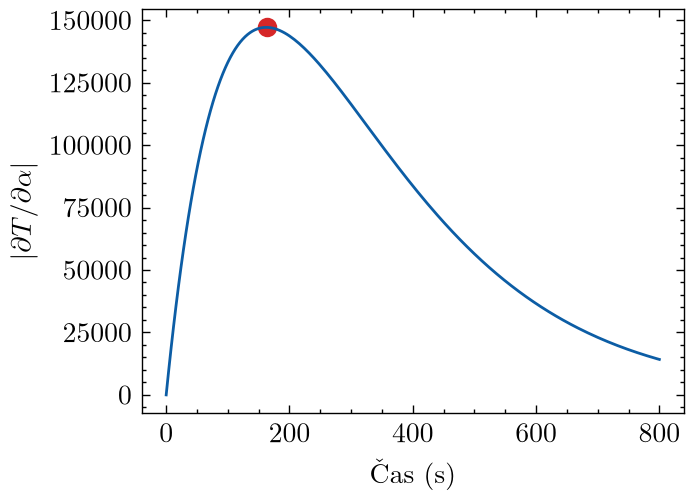

In [9]:
t = torch.linspace(0., 800., 201)  # čas [s]
alpha = torch.tensor(1e-4, requires_grad=True)  # [m²/s]
k = torch.pi / 0.4  # délka tyče 0,4 m

dT = 40 * torch.exp(-alpha * k**2 * t)
S = torch.stack([
    torch.autograd.grad(T_i, alpha, retain_graph=True)[0]
    for T_i in dT
])

i = S.abs().argmax()
plt.figure(dpi=200)
plt.plot(t, S.abs())
plt.scatter(t[i], S[i].abs(), color="tab:red")
plt.xlabel("Čas (s)")
plt.ylabel(r"$|\partial T/\partial \alpha|$")
plt.show()

## Diagnostika: sledování jednotlivých členů ztráty

*Navazuje na slide 11: Diagnostika; opakuje inverzní úlohu ze slidu 8.*

Samotný pokles celkové ztráty neukazuje, zda model současně splňuje rovnici, měření i okrajové podmínky. Proto zde zopakujeme odhad $q$ s kvadratickým modelem a při každém kroku před aktualizací parametrů uložíme zvlášť `loss_fyz`, `loss_data` a `loss_okr` do slovníku `historie`.

Graf se svislou logaritmickou osou umožňuje sledovat členy i při rozdílech několika řádů. Klesající křivky ukazují zlepšování příslušných požadavků. Pokud některý člen stagnuje na vysoké hodnotě nebo výrazně kolísá, je třeba prověřit škálování, váhy ztrát, vhodnost modelu nebo nastavení optimalizace. Rychlý pokles jediného členu sám o sobě nestačí. Vypsané $q$ opět porovnáme s očekávanou hodnotou 1.

Tato buňka realizuje sledování ztrát. Slide doporučuje také vyhodnotit reziduum na hustší nezávislé mřížce a opakovat trénování s jinou inicializací; tyto kontroly zde nejsou implementované. U současného kvadratického modelu je navíc $\phi''=2a$ konstantní, takže fyzikální reziduum nezávisí na poloze. Pro obecnou neuronovou síť by kontrola mezi trénovacími body mohla odhalit lokální porušení rovnice.


Odhad q = 0.9938


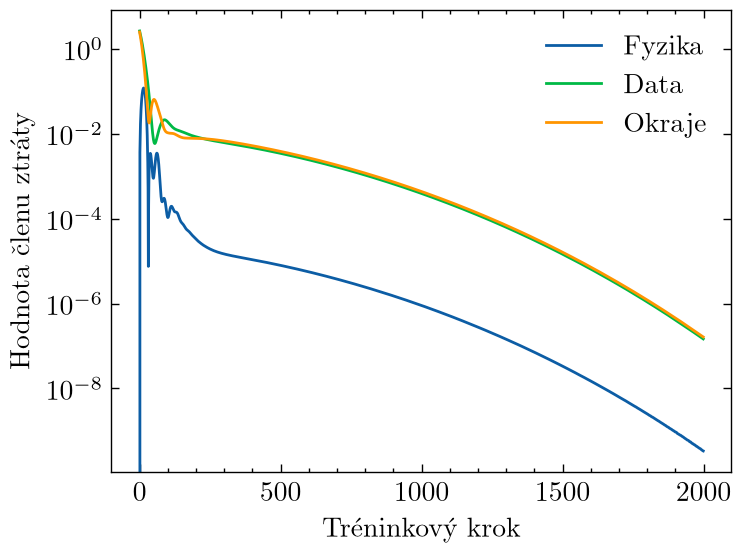

In [10]:
x = torch.linspace(0.1, 0.9, 5, requires_grad=True)
theta = torch.zeros(3, requires_grad=True)  # koeficienty a, b, c
q = torch.tensor(0.0, requires_grad=True)

optimizer = torch.optim.Adam([theta, q], lr=0.03)
historie = {"Fyzika": [], "Data": [], "Okraje": []}

for _ in range(2000):
    optimizer.zero_grad()

    a, b, c = theta
    phi = a * x**2 + b * x + c

    # Derivace potenciálu podle x a reziduum Poissonovy rovnice
    (dphi,) = torch.autograd.grad(phi.sum(), x, create_graph=True)
    (ddphi,) = torch.autograd.grad(dphi.sum(), x, create_graph=True)
    loss_fyz = (ddphi + q).square().mean()

    # Jedno měření uvnitř a dvě předepsané okrajové hodnoty
    phi_stred = 0.25 * a + 0.5 * b + c
    loss_data = (phi_stred - 1.625).square()
    loss_okr = ((c - 1).square() + (a + b + c - 2).square()) / 2
    
    historie["Fyzika"].append(loss_fyz.item())
    historie["Data"].append(loss_data.item())
    historie["Okraje"].append(loss_okr.item())
    
    loss = loss_fyz + loss_data + loss_okr
    loss.backward()
    optimizer.step()

print(f"Odhad q = {q.item():.4f}")  # očekáváme přibližně 1

import matplotlib.pyplot as plt
import scienceplots 
plt.style.use("science")

plt.figure(figsize=(4,3),dpi=200)
for nazev, hodnoty in historie.items():
    plt.semilogy(hodnoty, label=nazev)

plt.xlabel("Tréninkový krok")
plt.ylabel("Hodnota členu ztráty")
plt.legend()
plt.show()